# Training on multiple GPUs

<figure>
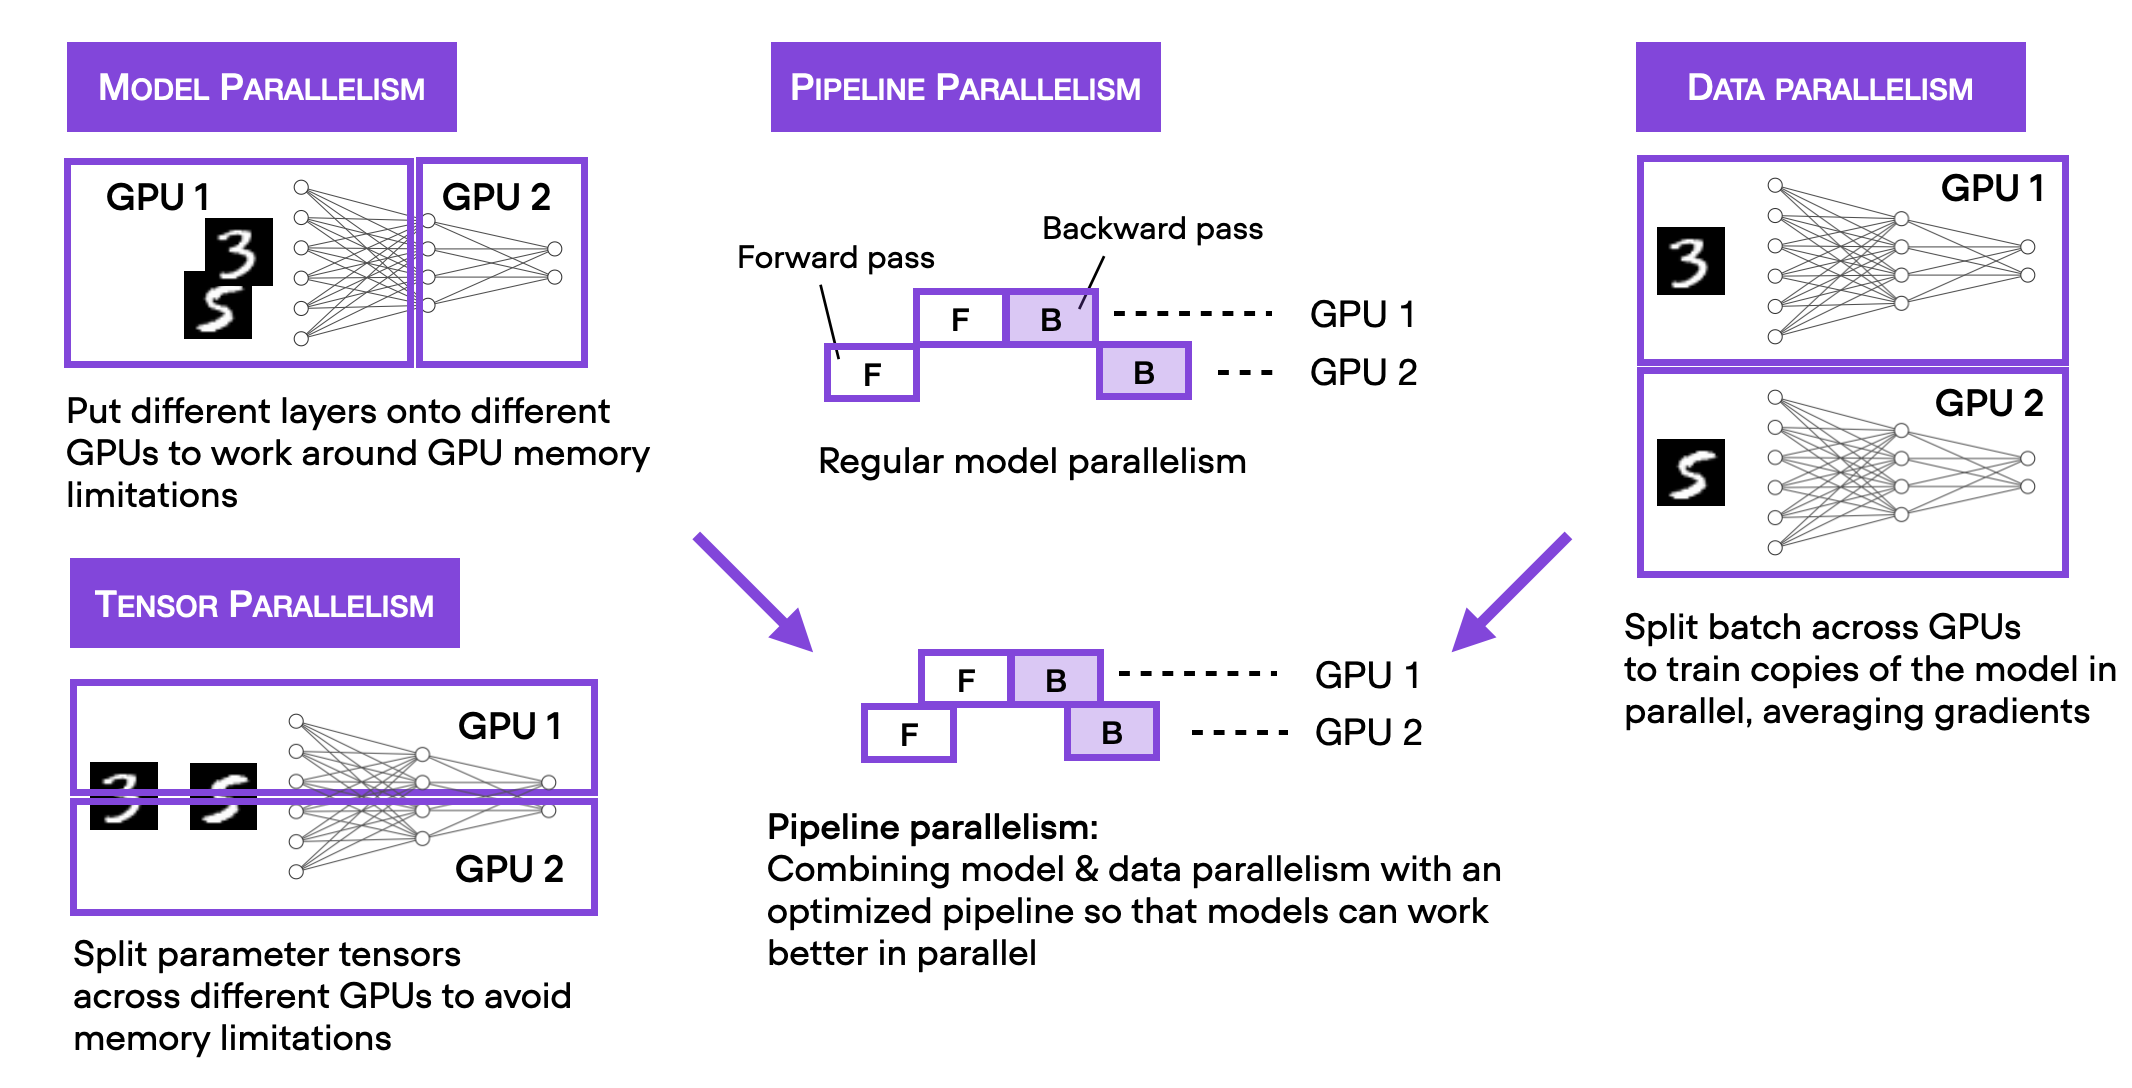
<figcaption aria-hidden="true">Common forms of parallelism during
training. Taken from <span class="citation"
data-cites="raschka2023sometechniquestomakeyourpytorchmodel">Raschka
(2023)</span></figcaption>
</figure>

Metis can take advantage of multiple GPUs located in the same machine
via *data parallelism*, wherein indentical copies of the model on
separate GPUs are fed with different batches of data, their gradients
aggregated and the overall parameter update copied to each GPU. Whilst
more sophisticated forms of parallelism are possible, and often required
at larger scales, we do not support them due to the complexity they
introduce.

## From one to four GPUs

Recall our usual single-GPU command,

``` bash
uv run train.py --config-name default dataset=sirds
```

To use four GPUs on one machine, set `num_gpus`:

``` bash
uv run train.py --config-name default dataset=sirds num_gpus=4
```

`train.py` starts one worker process per GPU itself, so everything else
(Hydra output directories, checkpoints, wandb logging, `--multirun`
sweeps) works exactly as it does on one GPU.

In cases where you want to use only a subset of the GPUs, the
`CUDA_VISIBLE_DEVICES` environment variable can be used to restrict the
GPUs visible to `train.py`. For example, to train on only GPUs `2` and
`3`:

``` bash
CUDA_VISIBLE_DEVICES=2,3 uv run train.py --config-name default dataset=sirds num_gpus=2
```

## Batch size

`batch_size` is the global batch size across all GPUs. It must be
divisible by `num_gpus`. For example, `batch_size=128` with four GPUs
gives each GPU 32 samples per optimizer step.

## Troubleshooting

Common checks when a job fails to start:

-   Confirm `nvidia-smi` lists at least `num_gpus` visible GPUs.
-   Confirm `batch_size` is divisible by `num_gpus`.
-   Set `NCCL_DEBUG=INFO` before the command when diagnosing NCCL
    initialization or communication failures.

Raschka, Sebastian. 2023. “Some Techniques to Make Your PyTorch Models
Train (Much) Faster.”
<https://sebastianraschka.com/blog/2023/pytorch-faster.html>.